# 02 · Preprocessing & features

**Goal:** check the cleaned data and test new feature ideas.
Features that prove useful are then added to `add_features()` in `src/preprocess.py`.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # lets the notebook import src/

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

sns.set_theme(style="whitegrid")
ACCENT = "#941B50"
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)

In [2]:
from src.preprocess import load_raw, clean, add_features

df = add_features(clean(load_raw()))
df.dtypes

customerID               str
gender                   str
SeniorCitizen          int64
Partner                  str
Dependents               str
tenure                 int64
PhoneService             str
MultipleLines            str
InternetService          str
OnlineSecurity           str
OnlineBackup             str
DeviceProtection         str
TechSupport              str
StreamingTV              str
StreamingMovies          str
Contract                 str
PaperlessBilling         str
PaymentMethod            str
MonthlyCharges       float64
TotalCharges         float64
Churn                  int64
NumServices            int64
TenureGroup         category
dtype: object

## 1. Checks after cleaning

In [3]:
assert df["customerID"].is_unique
assert df["TotalCharges"].notna().all()
assert set(df["Churn"].unique()) == {0, 1}
print("All checks passed |", df.shape)

All checks passed | (7043, 23)


## 2. Do the existing features help?

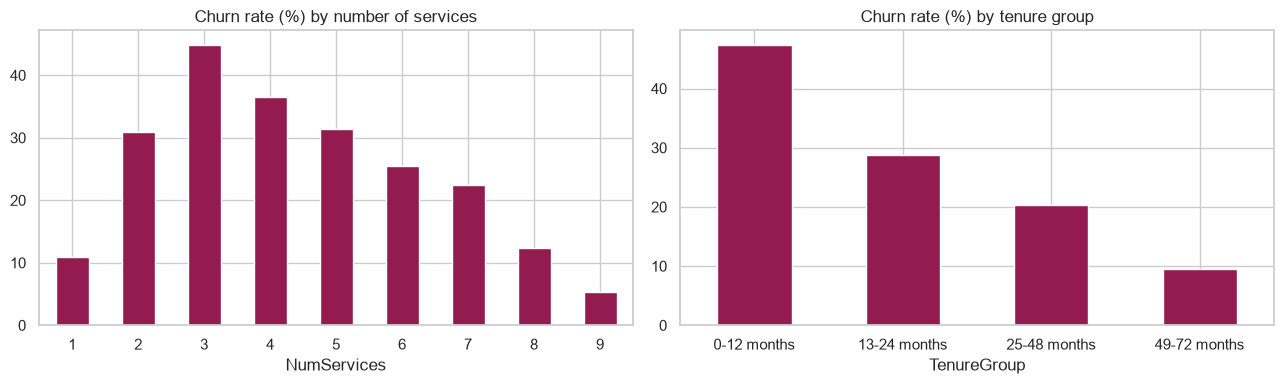

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.groupby("NumServices")["Churn"].mean().mul(100).plot.bar(ax=axes[0], color=ACCENT, rot=0, title="Churn rate (%) by number of services")
df.groupby("TenureGroup")["Churn"].mean().mul(100).plot.bar(ax=axes[1], color=ACCENT, rot=0, title="Churn rate (%) by tenure group")
plt.tight_layout(); plt.show()

## 3. Test new feature ideas

In [5]:
test = df.copy()

# Average charge per month of tenure: did the price change over time?
test["AvgChargePerMonth"] = test["TotalCharges"] / test["tenure"].replace(0, 1)
test["PriceIncrease"] = test["MonthlyCharges"] - test["AvgChargePerMonth"]

# Commitment and payment behaviour
test["HasLongContract"] = (test["Contract"] != "Month-to-month").astype(int)
test["AutoPayment"] = test["PaymentMethod"].str.contains("automatic").astype(int)

# Protection services (security + backup + device protection + tech support)
protect = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
test["NumProtection"] = (test[protect] == "Yes").sum(axis=1)

for col in ["HasLongContract", "AutoPayment", "NumProtection"]:
    print(test.groupby(col)["Churn"].mean().mul(100).round(1).rename(f"churn % by {col}"), "\n")

HasLongContract
0    42.7
1     6.8
Name: churn % by HasLongContract, dtype: float64 

AutoPayment
0    34.7
1    16.0
Name: churn % by AutoPayment, dtype: float64 

NumProtection
0    29.8
1    38.9
2    23.8
3    12.4
4     5.3
Name: churn % by NumProtection, dtype: float64 



In [6]:
test[["AvgChargePerMonth", "PriceIncrease", "Churn"]].corr()["Churn"].round(3)

AvgChargePerMonth    0.193
PriceIncrease       -0.010
Churn                1.000
Name: Churn, dtype: float64

## 4. Decision

| Feature | Churn rate across values | Decision |
|---|---|---|
| `HasLongContract` | 42.7% (no) vs 6.8% (yes) | Not added: redundant with `Contract`, already in the data |
| `AutoPayment` | 34.7% (no) vs 16.0% (yes) | Strong signal, tested in notebook 03b |
| `NumProtection` | 29.8% (0) → 38.9% (1) → 23.8% (2) → 12.4% (3) → 5.3% (4) | Strong signal, tested in notebook 03b |
| `AvgChargePerMonth` | correlation with churn: 0.19 | Redundant with `MonthlyCharges`, tested in notebook 03b |
| `PriceIncrease` | correlation with churn: -0.01 | No signal: dropped |

**Note on `NumProtection`:** churn is lower with 0 protection services (29.8%) than with 1 (38.9%) because
the "0" group includes customers without internet service, who rarely churn. Above 1 service, each extra
protection service clearly reduces churn.

**Final decision: no extra feature is added to `src/preprocess.py`.**
In notebook 03b, adding `AutoPayment`, `NumProtection` and `AvgChargePerMonth` to the tuned XGBoost did not improve
the model (precision at 80% recall: 0.522 with the extra features vs 0.531 without; ROC-AUC 0.849 vs 0.850).
XGBoost already captures these patterns from the original columns (`PaymentMethod`, `OnlineSecurity`, `TechSupport`…),
so the simpler pipeline is kept. These features remain useful for **business communication**, for example in the
dashboard ("customers with automatic payment churn half as much").